# 입력 해상도 개선 — 나사 정렬 crop (합성 비율 0.25 고정)

**가설**: baseline 은 1024px 이미지를 256→224 로 줄여 작은 결함(약 40px)이 10px 안팎이 된다. 나사만 PCA 축으로 세워(머리가 위) 잘라내면
같은 계산량에서 해상도를 높일 수 있고 회전 변동도 없어져, 분류와 위치 성능이 모두 오를 것이다.

| 변형 | 입력 크기 | 원본 대비 배율 | 해상도(baseline=1) | 계산량(baseline=1) |
|---|---|---|---|---|
| baseline (기존 파이프라인) | 224×224 | 0.25 | 1.0× | 1.0× |
| `align_0.4` | 128×384 | 0.4 | 1.6× | 약 1.0× |
| `align_0.6` | 192×576 | 0.6 | 2.4× | 약 2.2× |

두 변형을 비교하면 "정렬 효과"와 "해상도 효과"를 어느 정도 나눠 볼 수 있다(`align_0.4`는 계산량이 같은데 해상도만 1.6배).

**통제 조건 — 기존 실험과 동일**: train/val 분할(seed 42), 합성 풀과 합성 0.25 구성(유형당 13장, 소스·대상은 train 안), ResNet-18, Adam 1e-4, weight 2.0, 40 epoch, val F2 최고 epoch 선택, patience 10, 시드 0~4.
바뀌는 것은 **입력 전처리(정렬 crop)와 그에 맞는 증강**뿐이다. 평가는 합성 0장의 real test 55장.

**위치 지표 기준 통일**: 정렬 프레임의 CAM 을 원본 프레임으로 역투영한 뒤 baseline 과 같은 224 중앙 crop 에서 GT 마스크와 비교한다 → 기존 Pixel AUROC / AUPRO 와 같은 기준.

선행 조건: `synthetic_resnet_experiment.ipynb` 를 먼저 돌려 합성 풀(`splits/synthetic_split.csv`)과 `runs.csv`·`cam_methods.csv` 가 있어야 한다(비교 기준으로 사용).
커널은 `screw_defect`.

In [1]:
import os, sys, time, copy
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() or not (ROOT / "splits").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("레포 루트를 찾지 못함")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import fbeta_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, LayerCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

from src.common.paths import SYNTHETIC_SPLIT_CSV, SYNTH_EXP_DIR
from src.common.utils import set_seed
from src.supervised.data import list_records
from src.supervised.dataset import val_transform
from src.supervised.model import build_model_bin
from src.supervised.loc_eval import load_mask, inv_normalize, _compute_pixel_metrics
from src.supervised import synth, align

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

W1105 11:42:47.162000 25872 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


device: cuda


## 1. 설정

In [2]:
QUICK = os.environ.get("SYNTH_QUICK") == "1"

RATIO = 0.25                                   # 합성 비율 고정
SEEDS = [0, 1, 2, 3, 4]
VARIANTS = {"align_0.4": 0.4, "align_0.6": 0.6}   # 이름 -> 원본 대비 배율
EPOCHS, PATIENCE, BAD_WEIGHT, BATCH, LR = 40, 10, 2.0, 16, 1e-4     # baseline 과 동일
SPLIT_SEED = 42
CAM_COMBOS = [("GradCAM", "layer4"), ("GradCAM", "layer3"), ("LayerCAM", "layer3"), ("GradCAM++", "layer3")]
METHODS = {"GradCAM": GradCAM, "GradCAM++": GradCAMPlusPlus, "LayerCAM": LayerCAM}

if QUICK:
    SEEDS, VARIANTS, EPOCHS = [0], {"align_0.4": 0.4}, 3
TAG = "_quick" if QUICK else ""
RUNS_CSV = os.path.join(SYNTH_EXP_DIR, f"align_runs{TAG}.csv")
MODEL_DIR = os.path.join(SYNTH_EXP_DIR, f"models_align{TAG}")
os.makedirs(MODEL_DIR, exist_ok=True)
print("QUICK" if QUICK else "FULL", "| variants", VARIANTS, "| seeds", SEEDS, "| epochs", EPOCHS)

FULL | variants {'align_0.4': 0.4, 'align_0.6': 0.6} | seeds [0, 1, 2, 3, 4] | epochs 40


## 2. 데이터 — 기존 실험과 같은 분할 · 같은 합성 0.25 구성

In [3]:
CLASS_NAMES = ["good", "type1", "type2", "type3", "type4", "type5"]
def collect(split):
    return [{"path": r["path"], "type": r["class"], "label": 0 if r["class"] == "good" else 1, "mask": r["mask"]}
            for r in list_records(split, CLASS_NAMES)]

real_train, test_recs = collect("train"), collect("test")
tr_idx, val_idx = train_test_split(np.arange(len(real_train)), test_size=0.2,
                                   stratify=[r["type"] for r in real_train], random_state=SPLIT_SEED)
tr_recs = [real_train[i] for i in tr_idx]; val_recs = [real_train[i] for i in val_idx]
P = lambda rs: {r["path"] for r in rs}
assert not (P(tr_recs) & P(val_recs)) and not (P(tr_recs) & P(test_recs)) and not (P(val_recs) & P(test_recs))

pool = synth.load_pool(SYNTHETIC_SPLIT_CSV)
assert pool is not None, "합성 풀이 없다 — 먼저 synthetic_resnet_experiment.ipynb 를 실행하세요"
n_normal = sum(r["type"] == "good" for r in tr_recs)
alloc = synth.allocate(n_normal, RATIO)
synth_recs = synth.take(pool, alloc)
assert {r["source"] for r in synth_recs} <= P(tr_recs), "합성 소스가 train 밖에서 왔다"
assert not (P(synth_recs) & (P(val_recs) | P(test_recs)))
train_recs = tr_recs + synth_recs
print(f"train {len(tr_recs)} (정상 {n_normal} + real 결함 {len(tr_recs)-n_normal}) + 합성 {len(synth_recs)} {alloc} = {len(train_recs)}"
      f" | val {len(val_recs)} | test {len(test_recs)}")

train 340 (정상 260 + real 결함 80) + 합성 65 {'type1': 13, 'type2': 13, 'type3': 13, 'type4': 13, 'type5': 13} = 405 | val 85 | test 55


## 3. 정렬 결과 확인 (직접 눈으로)

모든 나사가 **머리가 위**로 세워져 있어야 한다. 정상 / 유형별 결함 / **합성** / (이전 분할이 반만 잡던) 반사 심한 이미지를 섞어서 본다.
머리가 아래로 뒤집힌 이미지가 보이면 알려 주세요 — 방향은 "폭이 넓은 쪽 = 머리" 규칙이라 결함으로 폭이 바뀐 이미지에서 틀릴 수 있다.

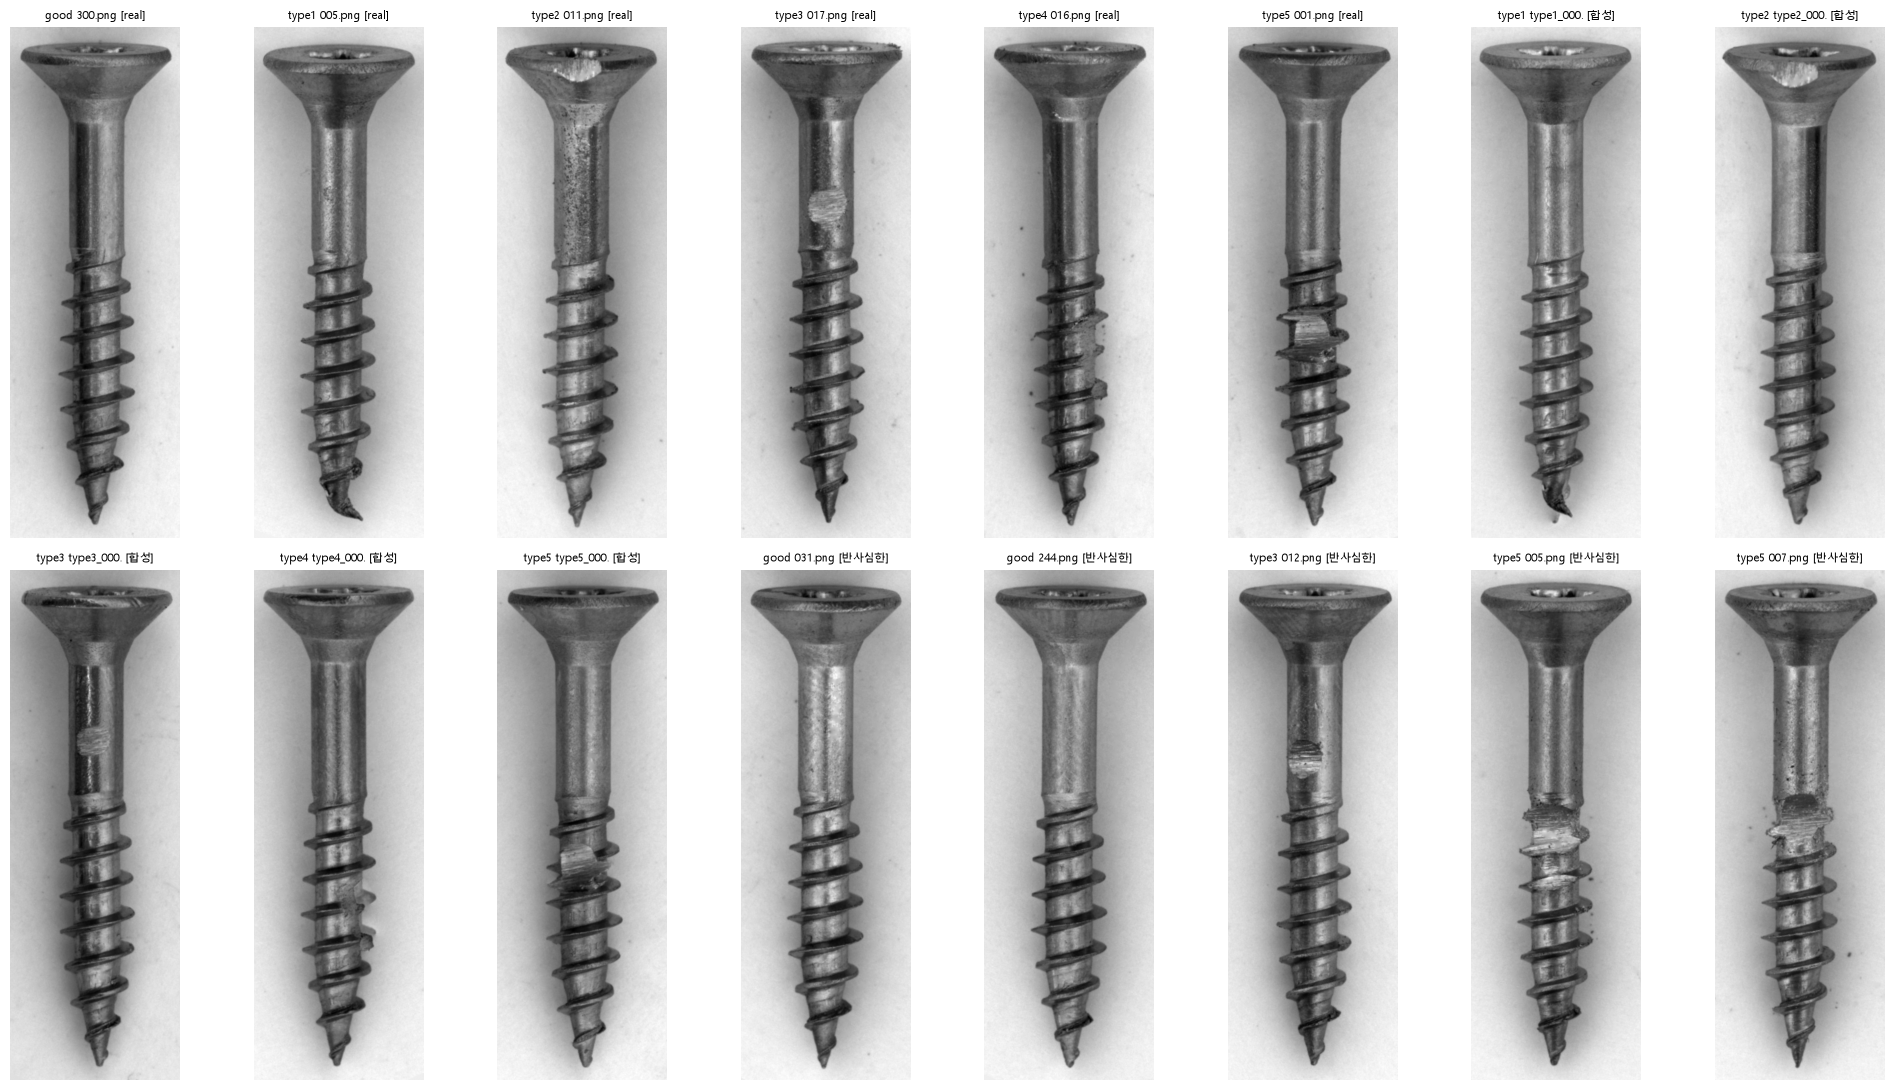

나사 길이 min/median/max = 847/904/920  (이상치 <800: 0장)


In [4]:
broken = [r for r in real_train if (r["type"], os.path.basename(r["path"])) in
          {("good", "031.png"), ("good", "244.png"), ("type3", "012.png"), ("type5", "005.png"), ("type5", "007.png")}]
show = ([next(r for r in tr_recs if r["type"] == t) for t in CLASS_NAMES]
        + [next(r for r in synth_recs if r["type"] == t) for t in synth.TYPES] + broken)[:16]
fig, axs = plt.subplots(2, 8, figsize=(20, 11))
for a, r in zip(axs.ravel(), show):
    a.imshow(align.align_full(r["path"])[0], cmap="gray")
    kind = "합성" if r in synth_recs else ("반사심한" if r in broken else "real")
    a.set_title(f"{r['type']} {os.path.basename(r['path'])[:10]} [{kind}]", fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()

# 나사 길이 점검: 전부 정상 범위(약 800~930)여야 분할이 잘 된 것
lens = np.array([align.align_full(r["path"])[2] for r in real_train + test_recs])
print(f"나사 길이 min/median/max = {lens.min():.0f}/{np.median(lens):.0f}/{lens.max():.0f}  (이상치 <800: {(lens < 800).sum()}장)")

## 4. 데이터셋 · 증강 · 학습/평가 함수

정렬된 입력은 방향이 고정되어 있으므로 증강을 바꾼다: baseline 의 `RandomRotation(180)`·수직 뒤집기는 **제거**(머리 방향을 망가뜨림), 대신 작은 회전(±8°)·이동·배율 + **좌우 반전**(나사 축 기준 대칭)과 밝기/대비를 쓴다.

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TRAIN_TF = transforms.Compose([
    transforms.RandomAffine(degrees=8, translate=(0.04, 0.03), scale=(0.9, 1.1), fill=200),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
EVAL_TF = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

_CACHE = {}
def aligned_pil(path, scale):
    k = (path, scale)
    if k not in _CACHE:
        _CACHE[k] = Image.fromarray(align.align_scaled(path, scale))
    return _CACHE[k]

class AlignedDS(Dataset):
    def __init__(self, recs, scale, tf): self.recs, self.scale, self.tf = recs, scale, tf
    def __len__(self): return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]
        return self.tf(aligned_pil(r["path"], self.scale)), r["label"]

def loader(recs, scale, train):
    return DataLoader(AlignedDS(recs, scale, TRAIN_TF if train else EVAL_TF), batch_size=BATCH, shuffle=train, num_workers=0)

def train_one(scale, seed):
    set_seed(seed)
    train_loader, val_loader = loader(train_recs, scale, True), loader(val_recs, scale, False)
    model = build_model_bin("resnet18").to(device)
    crit = nn.CrossEntropyLoss(weight=torch.tensor([1.0, BAD_WEIGHT]).to(device))
    opt = optim.Adam(model.parameters(), lr=LR)
    best_f2, best_ep, best_state, bad = 0.0, 0, copy.deepcopy(model.state_dict()), 0
    for ep in range(EPOCHS):
        model.train()
        for imgs, y in train_loader:
            opt.zero_grad(); crit(model(imgs.to(device)), y.to(device)).backward(); opt.step()
        model.eval(); yt, yp = [], []
        with torch.no_grad():
            for imgs, y in val_loader:
                yp.extend(model(imgs.to(device)).argmax(1).cpu().numpy()); yt.extend(y.numpy())
        f2 = fbeta_score(yt, yp, beta=2, pos_label=1, zero_division=0)
        if f2 > best_f2:
            best_f2, best_ep, best_state, bad = f2, ep + 1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
        if bad >= PATIENCE:
            break
    model.load_state_dict(best_state); model.eval()
    return model, best_f2, best_ep

# ---- 평가: 분류 + 위치(정렬 프레임 CAM → 원본 프레임 역투영 → baseline 과 같은 224 프레임)
defects = [r for r in test_recs if r["label"] == 1]
GT = np.stack([load_mask(r["mask"]) for r in defects])
def defect_batch(scale):
    return torch.stack([EVAL_TF(aligned_pil(r["path"], scale)) for r in defects]).to(device)

def cam_eval_maps(model, method, layer, scale):
    x = defect_batch(scale)
    with METHODS[method](model=model, target_layers=[getattr(model, layer)[-1]]) as cam:
        cams = cam(input_tensor=x, targets=[ClassifierOutputTarget(1)] * len(x))        # (N, H, W) 정렬 프레임
    return [align.cam_to_eval_frame(c, r["path"]) for c, r in zip(cams, defects)]       # 각 (224, 224)

def evaluate(model, scale):
    tl = loader(test_recs, scale, False)
    yt, yp, pr = [], [], []
    with torch.no_grad():
        for imgs, y in tl:
            lg = model(imgs.to(device))
            yp.extend(lg.argmax(1).cpu().numpy()); pr.extend(torch.softmax(lg, 1)[:, 1].cpu().numpy()); yt.extend(y.numpy())
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    out = dict(precision=precision_score(yt, yp, zero_division=0), recall=recall_score(yt, yp),
               f2=fbeta_score(yt, yp, beta=2, pos_label=1, zero_division=0), img_auroc=roc_auc_score(yt, pr),
               tn=tn, fp=fp, fn=fn, tp=tp)
    for m, l in CAM_COMBOS:
        res = _compute_pixel_metrics(cam_eval_maps(model, m, l, scale), list(GT))
        out[f"pa_{m}_{l}"], out[f"aupro_{m}_{l}"] = res["pixel_auroc"], res["aupro"]
    return out
print("정의 완료 | 입력 크기:", {k: (round(align.CANVAS_H * s), round(align.CANVAS_W * s)) for k, s in VARIANTS.items()})

정의 완료 | 입력 크기: {'align_0.4': (384, 128), 'align_0.6': (576, 192)}


## 5. 실행 — (변형 × 시드) 학습 후 평가

`outputs/synth_exp/align_runs.csv` 에 누적 저장(이어서 실행 가능), 모델은 `models_align/` 에 저장.

In [6]:
done = pd.read_csv(RUNS_CSV) if os.path.exists(RUNS_CSV) else pd.DataFrame()
rows = done.to_dict("records")
done_keys = {(r["variant"], int(r["seed"])) for r in rows}
total = len(VARIANTS) * len(SEEDS)
for seed in SEEDS:
    for name, scale in VARIANTS.items():
        if (name, seed) in done_keys:
            continue
        t0 = time.time()
        model, vf2, bep = train_one(scale, seed)
        torch.save(model.state_dict(), os.path.join(MODEL_DIR, f"{name}_s{seed}.pth"))
        res = evaluate(model, scale)
        rows.append(dict(variant=name, scale=scale, seed=seed, best_epoch=bep, val_f2=vf2, seconds=round(time.time() - t0), **res))
        pd.DataFrame(rows).to_csv(RUNS_CSV, index=False)
        print(f"[{len(rows):2d}/{total}] {name} seed={seed} | val F2 {vf2:.3f} (ep {bep}) | test F2 {res['f2']:.3f} "
              f"R {res['recall']:.3f} P {res['precision']:.3f} | LayerCAM/L3 pixAUROC {res['pa_LayerCAM_layer3']:.3f} "
              f"AUPRO {res['aupro_LayerCAM_layer3']:.3f} | {time.time()-t0:.0f}s")
        del model; torch.cuda.empty_cache()
runs = pd.DataFrame(rows); print("완료:", len(runs), "runs")

[ 2/10] align_0.6 seed=0 | val F2 1.000 (ep 4) | test F2 0.870 R 0.842 P 1.000 | LayerCAM/L3 pixAUROC 0.994 AUPRO 0.983 | 109s
[ 3/10] align_0.4 seed=1 | val F2 1.000 (ep 10) | test F2 0.870 R 0.842 P 1.000 | LayerCAM/L3 pixAUROC 0.991 AUPRO 0.977 | 103s
[ 4/10] align_0.6 seed=1 | val F2 1.000 (ep 4) | test F2 0.870 R 0.842 P 1.000 | LayerCAM/L3 pixAUROC 0.991 AUPRO 0.967 | 95s
[ 5/10] align_0.4 seed=2 | val F2 1.000 (ep 12) | test F2 0.870 R 0.842 P 1.000 | LayerCAM/L3 pixAUROC 0.994 AUPRO 0.982 | 91s
[ 6/10] align_0.6 seed=2 | val F2 1.000 (ep 6) | test F2 0.870 R 0.842 P 1.000 | LayerCAM/L3 pixAUROC 0.994 AUPRO 0.982 | 112s
[ 7/10] align_0.4 seed=3 | val F2 1.000 (ep 6) | test F2 0.957 R 0.947 P 1.000 | LayerCAM/L3 pixAUROC 0.990 AUPRO 0.974 | 72s
[ 8/10] align_0.6 seed=3 | val F2 1.000 (ep 3) | test F2 0.769 R 0.737 P 0.933 | LayerCAM/L3 pixAUROC 0.986 AUPRO 0.953 | 91s
[ 9/10] align_0.4 seed=4 | val F2 1.000 (ep 9) | test F2 0.957 R 0.947 P 1.000 | LayerCAM/L3 pixAUROC 0.991 AUPRO

## 6. 결과 — 기존(baseline) 입력 vs 정렬 crop

기준은 **같은 시드·같은 합성 0.25** 로 학습한 기존 파이프라인 결과(`runs.csv`, 위치는 `cam_methods.csv`)이다. `Δ` 는 baseline(합성 0.25) 대비 평균 차이, `p` 는 시드로 짝지은 t-test.
합성 없음(0.0) 행은 참고용.

In [7]:
base_runs = pd.read_csv(os.path.join(SYNTH_EXP_DIR, "runs.csv"))
base_cam = pd.read_csv(os.path.join(SYNTH_EXP_DIR, "cam_methods.csv"))
runs = pd.read_csv(RUNS_CSV)
seeds = sorted(runs["seed"].unique())

def base_series(ratio, key):
    if key in ("f2", "recall", "precision", "img_auroc"):
        d = base_runs[(base_runs.ratio == ratio) & base_runs.seed.isin(seeds)].set_index("seed")[key]
    else:                                   # "pa_Method_layer" / "aupro_Method_layer"
        kind, m, l = key.split("_", 2)
        d = base_cam[(base_cam.ratio == ratio) & (base_cam.method == m) & (base_cam.layer == l) & base_cam.seed.isin(seeds)]
        d = d.set_index("seed")["pixel_auroc" if kind == "pa" else "aupro"]
    return d.sort_index()

def series(name, key):
    return runs[runs.variant == name].set_index("seed")[key].sort_index()

def make_table(keys_labels):
    out = []
    for key, label in keys_labels:
        ref = base_series(0.25, key)
        row = {"지표": label, "baseline 합성0.0": f"{base_series(0.0, key).mean():.3f}",
               "baseline 합성0.25": f"{ref.mean():.3f} ± {ref.std(ddof=1):.3f}"}
        for name in VARIANTS:
            s = series(name, key); d = s - ref.loc[s.index]
            p = stats.ttest_rel(s, ref.loc[s.index]).pvalue if len(s) > 1 else float("nan")
            row[name] = f"{s.mean():.3f} ± {s.std(ddof=1) if len(s) > 1 else 0:.3f}"
            row[f"Δ {name}"] = f"{d.mean():+.3f} (p={p:.2f})"
        out.append(row)
    return pd.DataFrame(out)

print("=== 분류 (real test 55장) ===")
display(make_table([("f2", "Test F2"), ("recall", "Recall"), ("precision", "Precision"), ("img_auroc", "Image AUROC")]))
print("=== 위치 (결함 19장, baseline 과 같은 224 프레임) ===")
display(make_table([(f"{k}_{m}_{l}", f"{'Pixel AUROC' if k == 'pa' else 'AUPRO'} {m}/{l}")
                    for m, l in CAM_COMBOS for k in ("pa", "aupro")]))

=== 분류 (real test 55장) ===


,지표,baseline 합성0.0,baseline 합성0.25,align_0.4,Δ align_0.4,align_0.6,Δ align_0.6
0,Test F2,0.778,0.881 ± 0.040,0.914 ± 0.044,+0.033 (p=0.31),0.849 ± 0.045,-0.031 (p=0.07)
1,Recall,0.747,0.884 ± 0.044,0.895 ± 0.053,+0.011 (p=0.70),0.821 ± 0.047,-0.063 (p=0.03)
2,Precision,0.952,0.876 ± 0.102,1.000 ± 0.000,+0.124 (p=0.05),0.987 ± 0.030,+0.111 (p=0.05)
3,Image AUROC,0.969,0.959 ± 0.032,0.992 ± 0.015,+0.032 (p=0.08),0.991 ± 0.019,+0.031 (p=0.09)


=== 위치 (결함 19장, baseline 과 같은 224 프레임) ===


,지표,baseline 합성0.0,baseline 합성0.25,align_0.4,Δ align_0.4,align_0.6,Δ align_0.6
0,Pixel AUROC GradCAM/layer4,0.807,0.902 ± 0.043,0.985 ± 0.008,+0.084 (p=0.01),0.992 ± 0.004,+0.090 (p=0.01)
1,AUPRO GradCAM/layer4,0.556,0.808 ± 0.049,0.947 ± 0.023,+0.140 (p=0.01),0.970 ± 0.019,+0.163 (p=0.00)
2,Pixel AUROC GradCAM/layer3,0.928,0.937 ± 0.050,0.967 ± 0.025,+0.030 (p=0.30),0.984 ± 0.008,+0.047 (p=0.09)
3,AUPRO GradCAM/layer3,0.797,0.873 ± 0.071,0.934 ± 0.044,+0.062 (p=0.15),0.954 ± 0.023,+0.081 (p=0.04)
4,Pixel AUROC LayerCAM/layer3,0.914,0.970 ± 0.019,0.992 ± 0.001,+0.022 (p=0.07),0.992 ± 0.004,+0.022 (p=0.07)
5,AUPRO LayerCAM/layer3,0.762,0.923 ± 0.031,0.978 ± 0.003,+0.055 (p=0.01),0.975 ± 0.015,+0.053 (p=0.02)
6,Pixel AUROC GradCAM++/layer3,0.919,0.952 ± 0.025,0.973 ± 0.006,+0.021 (p=0.14),0.968 ± 0.016,+0.016 (p=0.28)
7,AUPRO GradCAM++/layer3,0.754,0.895 ± 0.011,0.909 ± 0.024,+0.014 (p=0.23),0.890 ± 0.055,-0.005 (p=0.82)


## 7. 눈으로 보기 — 같은 test 결함, baseline 입력 vs 정렬 입력 (LayerCAM / layer3)

열: 원본 / GT / baseline(합성 0.25) / 정렬 변형들. 모두 **원본 프레임(224)** 에 그려서 같은 기준으로 본다. 제목의 `p`는 bad 확률.
유형별 test 첫 장(고정 규칙)을 쓴다.

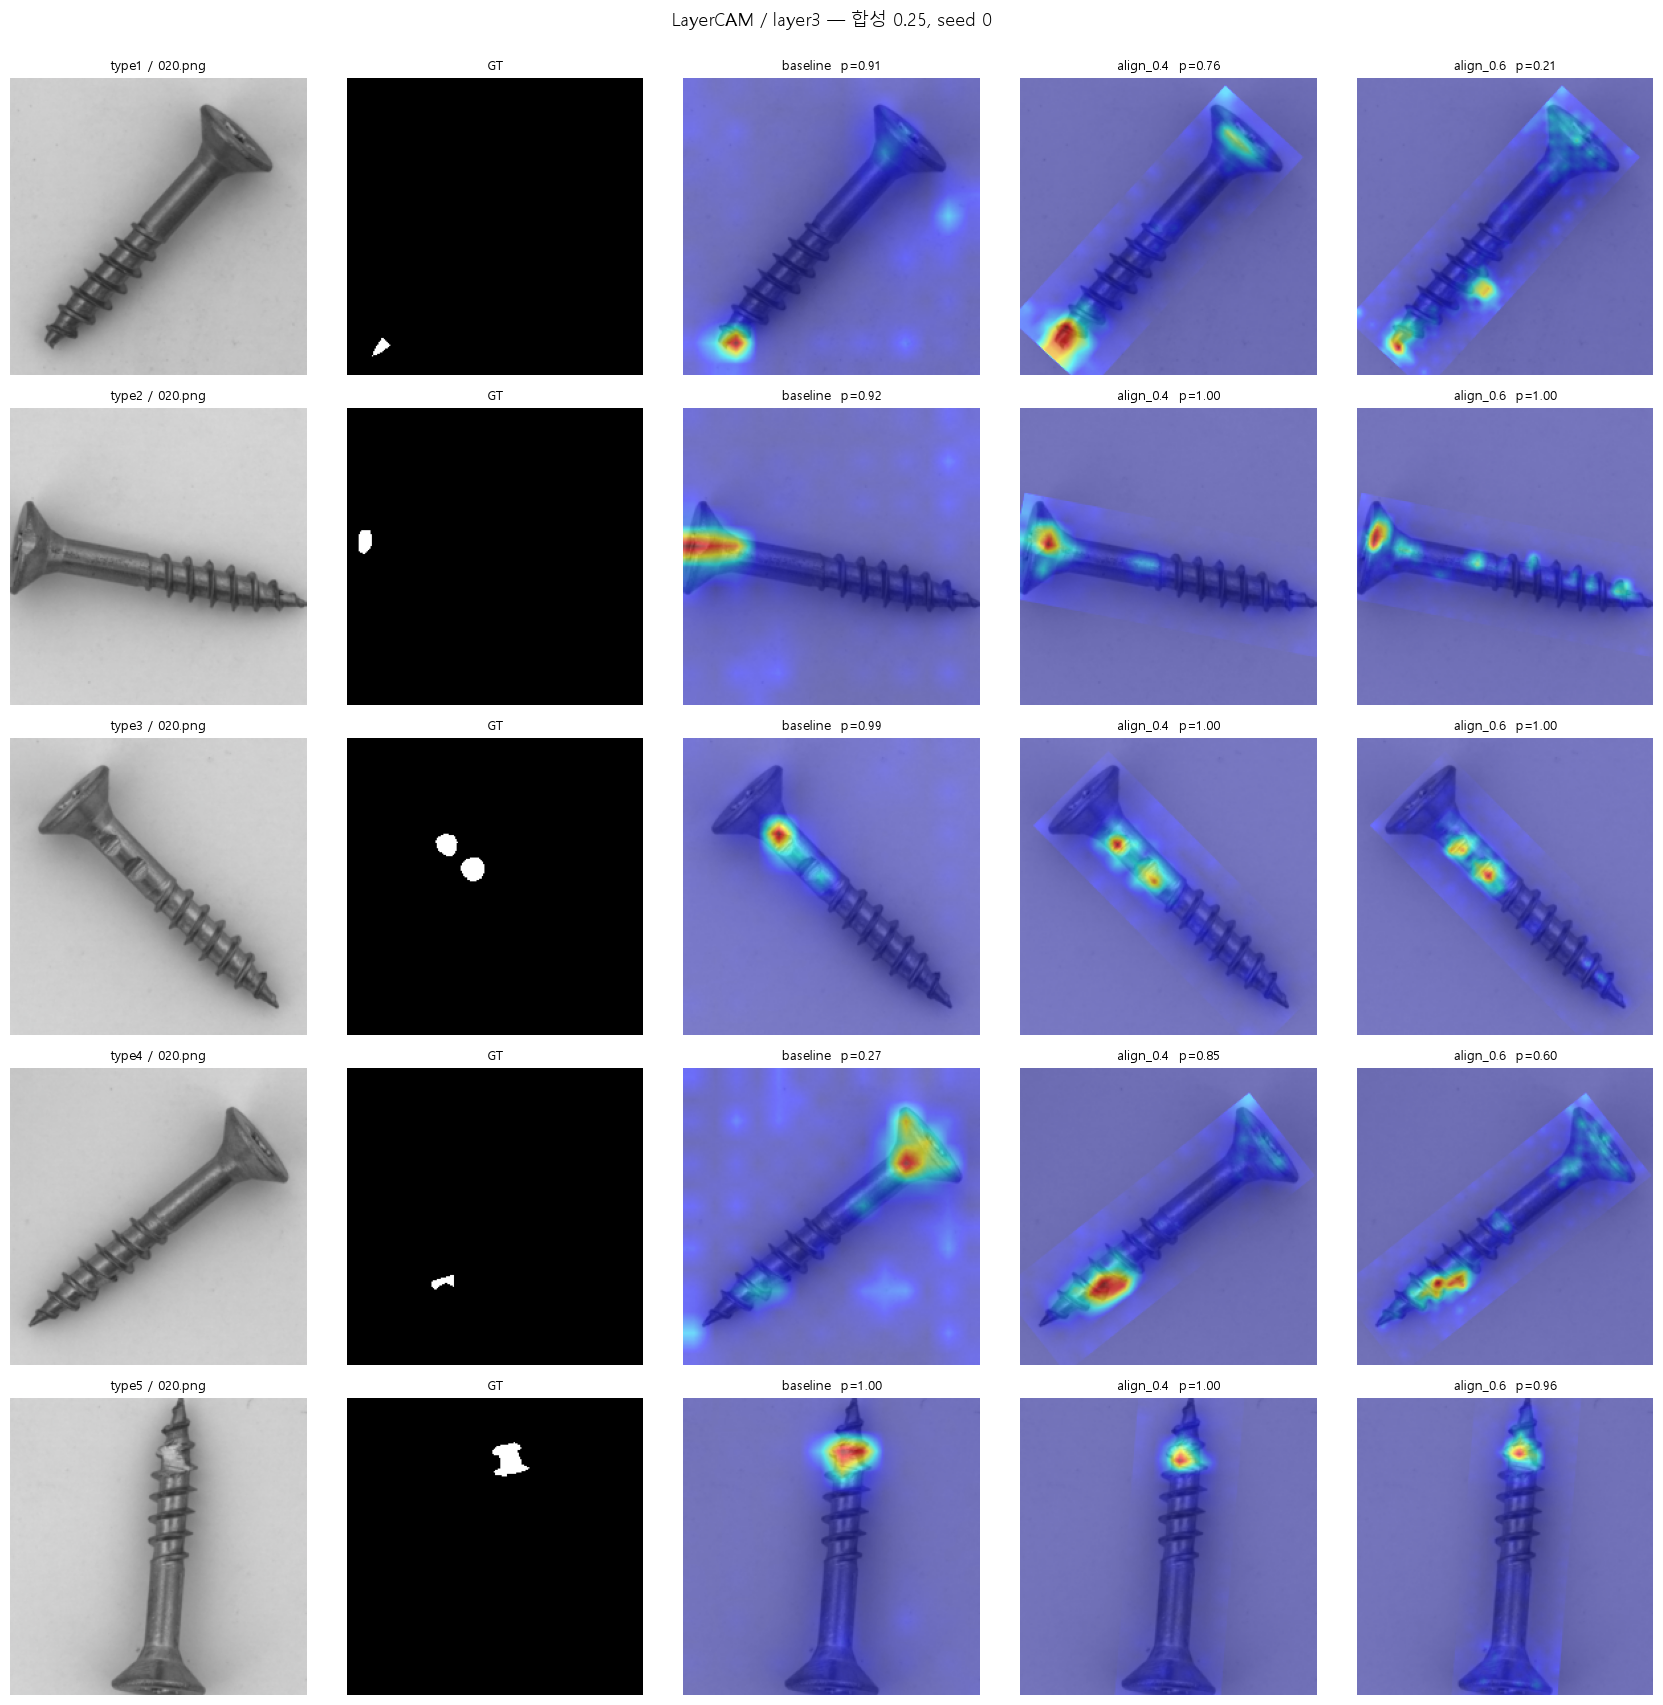

: 

In [ ]:
VIZ_SEED = seeds[0]
def base_model(ratio, seed):
    m = build_model_bin("resnet18").to(device)
    m.load_state_dict(torch.load(os.path.join(SYNTH_EXP_DIR, "models", f"r{ratio:.2f}_s{seed}.pth"), map_location=device)); m.eval()
    return m

first_idx = [next(i for i, r in enumerate(defects) if r["type"] == t) for t in synth.TYPES]
Xb = torch.stack([val_transform(Image.open(defects[i]["path"]).convert("RGB")) for i in first_idx]).to(device)
mb = base_model(RATIO, VIZ_SEED)
with LayerCAM(model=mb, target_layers=[mb.layer3[-1]]) as cam:
    base_maps = cam(input_tensor=Xb, targets=[ClassifierOutputTarget(1)] * len(Xb))
with torch.no_grad():
    base_p = torch.softmax(mb(Xb), 1)[:, 1].cpu().numpy()

var_maps, var_p = {}, {}
for name, scale in VARIANTS.items():
    m = build_model_bin("resnet18").to(device)
    m.load_state_dict(torch.load(os.path.join(MODEL_DIR, f"{name}_s{VIZ_SEED}.pth"), map_location=device)); m.eval()
    x = torch.stack([EVAL_TF(aligned_pil(defects[i]["path"], scale)) for i in first_idx]).to(device)
    with LayerCAM(model=m, target_layers=[m.layer3[-1]]) as cam:
        cams = cam(input_tensor=x, targets=[ClassifierOutputTarget(1)] * len(x))
    var_maps[name] = [align.cam_to_eval_frame(c, defects[i]["path"]) for c, i in zip(cams, first_idx)]
    with torch.no_grad():
        var_p[name] = torch.softmax(m(x), 1)[:, 1].cpu().numpy()

fig, axs = plt.subplots(len(first_idx), 3 + len(VARIANTS), figsize=(3.4 * (3 + len(VARIANTS)), 3.4 * len(first_idx)))
for row, gi in enumerate(first_idx):
    img = np.clip(inv_normalize(Xb[row].cpu()).numpy().transpose(1, 2, 0), 0, 1)
    axs[row, 0].imshow(img); axs[row, 0].set_title(f"{defects[gi]['type']} / {os.path.basename(defects[gi]['path'])}", fontsize=9)
    axs[row, 1].imshow(GT[gi], cmap="gray", vmin=0, vmax=1); axs[row, 1].set_title("GT", fontsize=9)
    axs[row, 2].imshow(show_cam_on_image(img, base_maps[row], use_rgb=True)); axs[row, 2].set_title(f"baseline  p={base_p[row]:.2f}", fontsize=9)
    for j, name in enumerate(VARIANTS):
        axs[row, 3 + j].imshow(show_cam_on_image(img, var_maps[name][row], use_rgb=True))
        axs[row, 3 + j].set_title(f"{name}  p={var_p[name][row]:.2f}", fontsize=9)
for a in axs.ravel(): a.axis("off")
fig.suptitle(f"LayerCAM / layer3 — 합성 0.25, seed {VIZ_SEED}", fontsize=13, y=1.0)
plt.tight_layout(); plt.show()

## 8. 해석 시 주의

- 결함 19장·시드 5개라 작은 Δ 는 효과로 보지 않는다(표의 p 와 표준편차를 함께 본다).
- 정렬 crop 은 **배경을 대부분 제거**하므로 위치 지표의 "쉬운 배경 픽셀"이 줄어든 것이 아니라, 원본 프레임으로 역투영해 baseline 과 같은 픽셀 집합에서 계산했다(CAM 은 캔버스 밖에서 0).
- 정렬 방향(머리 위)은 "폭이 넓은 쪽" 규칙이라 3번 그림에서 뒤집힌 이미지가 없는지 확인해야 한다.
- 효과가 해상도 때문인지 정렬 때문인지 더 가르려면, 정렬 없이 입력만 키운 대조군(예: Resize 448)을 추가로 돌려야 한다.